### TechPath ML Engine using Logistic Regression

**Team members:** Hellen Mutemi (179581) · Mediatrice Kasongo (190013) · Tumaini Wekesa (189813)

This is the final notebook of our ML engine it follows the stages of the data mining process which include:
1. **Business understanding** - what TechPath is and what the ML engine has to do in the app
2. **Data understanding** - the roadmap.sh dataset, its columns and missing values, and the EDA
3. **Data preparation** - cleaning the rows and the text
4. **Modelling** - the base model, the model comparison and the final model
5. **Evaluation** - final model vs base model on the held-out test set, explainability and testing with sample inputs
6. **Deployment** - exporting the model files the app loads



### 1.Identify the ML approach and algorithms that are relevant to the dataset & expected output of your application.
TechPath is an AI mobile app that builds a personalized career-skills roadmap for technology students. A student will type their career and the AI app will show the skills to learn, explain each one and show links to learning resources

**The ML engine** matches a student's text to the most relevant career path and then retrieves the closest skill nodes in the dataset. 
Our dataset labels every skill node with the `career_path` it belongs to meaning that this is a **supervised multi-class text classification** where given a piece of text describing a skill or interest, it predicts which career path it belongs to.
*Supervised* means the model learns from examples that already have the right answer (the career path), and *multi-class* means there are many possible answers and not just yes or no.

**The problem** - Many students know they want to work in tech but don't know which career path fits them or which skills to learn first.

**What the ML engine has to do in the app**
- **Input** - the student's own words about the work they want to do, e.g. "I want to build apps for banks"
- **Output** - the 3 most likely career paths with a probability for each, and the 5 skills on each path that are closest to what the student typed. The student picks a path and the app builds a staged roadmap from the same model
- Everything runs on the phone with no internet and no API key. The model is trained locally and is exported as small files that the app's Kotlin code loads

In [1]:
import re
import json
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, top_k_accuracy_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)   

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)


### 2.Critically detail the data cleaning process taken from exploration to the final dataset for modelling. As part of the EDA, derive at least 4 observations from the dataset
The dataset was scraped from the roadmap.sh Github repository(*https://github.com/nilbuild/developer-roadmap*) and a python script used to convert it from json to csv.

In [2]:
# Loading the raw dataset
raw = pd.read_csv("roadmap_dataset.csv")
print("Attributes (rows, columns)", raw.shape)
raw.head()

Attributes (rows, columns) (10634, 10)


,career_path,topic_slug,node_id,title,description,courses,articles,official_docs,videos,opensource
0,ai-agents,acting--tool-invocation,sHYd4KsKlmw5Im3nQ19W8,Acting / Tool Invocation,"Acting, also called tool invocation, is the step where the AI chooses a tool and runs it to get real-world data or t...",NaN,What are Tools in AI Agents? (https://huggingface.co/learn/agents-course/en/unit1/tools) | What is Tool Calling in A...,NaN,NaN,NaN
1,ai-agents,agent-loop,Eih4eybuYB3C2So8K0AT3,Agent Loop,"An agent loop is the cycle that lets an AI agent keep working toward a goal. First, the agent gathers fresh data fro...",NaN,What is an Agent Loop? (https://huggingface.co/learn/agents-course/en/unit1/agent-steps-and-structure) | Let's Build...,NaN,NaN,NaN
2,ai-agents,agno,PY5WTJgRnXiYeOM6BBUvn,Agno,Agno is a Python framework designed to streamline the process of building AI agents. It offers tools and abstraction...,NaN,NaN,Agno Docs (https://docs.agno.com/),Building Your First Agent With AGNO AGI ( Previously Phidata ) | For Complete Begineers (https://www.youtube.com/wat...,agno (https://github.com/agno-agi/agno)
3,ai-agents,anthropic-tool-use,1EZFbDHA5J5_5BPMLMxXb,Anthropic Tool Use,Anthropic Tool Use lets you connect a Claude model to real software functions so the agent can do useful tasks on it...,NaN,NaN,Anthropic Tool Use (https://docs.anthropic.com/en/docs/build-with-claude/tool-use/overview),NaN,NaN
4,ai-agents,api-requests,52qxjZILV-X1isup6dazC,API Requests,API requests let an AI agent ask another service for data or for an action. The agent builds a short message that fo...,NaN,Introduction to APIs - MDN Web Docs (https://developer.mozilla.org/en-US/docs/Learn_web_development/Extensions/Clien...,NaN,NaN,NaN


In [3]:
# Data types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10634 entries, 0 to 10633
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   career_path    10634 non-null  str  
 1   topic_slug     10615 non-null  str  
 2   node_id        10625 non-null  str  
 3   title          10632 non-null  str  
 4   description    10605 non-null  str  
 5   courses        299 non-null    str  
 6   articles       7000 non-null   str  
 7   official_docs  4647 non-null   str  
 8   videos         4297 non-null   str  
 9   opensource     447 non-null    str  
dtypes: str(10)
memory usage: 830.9 KB


**career_path** : the roadmap a skill belongs to, e.g. aws, blockchain
**topic_slug**, **node_id**: the internal identifiers from roadmap.sh
**title**, **description**: the skill name and its explanation
**courses**, **articles**, **official_docs**, **videos**, **opensource**: these are the learning resource links

### Missing Values

In [4]:
missing = pd.DataFrame({
    "missing count": raw.isna().sum(),
    "missing percentage":(raw.isna().mean()*100).round(1),
}).sort_values("missing count",ascending=False)
missing

,missing count,missing percentage
courses,10335,97.2
opensource,10187,95.8
videos,6337,59.6
official_docs,5987,56.3
articles,3634,34.2
description,29,0.3
topic_slug,19,0.2
node_id,9,0.1
title,2,0.0
career_path,0,0.0


### Data preparation


Dropping rows without `title` or `description` because these are the model's main input and if either one is missing it becomes unusable. But the resource columns are empty but we keep them because not every skill has a course

In [5]:
df = raw.copy()
before = len(df)

df = df.dropna(subset=["title", "description"])
print(f"Dropped {before-len(df)} rows with missing title/description, current is {len(df)} rows")

Dropped 30 rows with missing title/description, current is 10604 rows


### Duplicates

We look for duplicates in general, then we go on to drop rows which have the same career_path and title because we consider these duplicates

In [6]:
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before-len(df)} duplicate rows, current rows are {len(df)}")

before = len(df)
df = df.drop_duplicates(subset=["career_path", "title"])
print(f"Dropped {before-len(df)} rows, current rows are now, {len(df)}")


Dropped 0 duplicate rows, current rows are 10604
Dropped 308 rows, current rows are now, 10296


### Cleaning the text
Some descriptions can contain leftovers from scraping, like markdown headings and links and raw urls, so we therefore remove them


In [7]:
noisy = df[df["description"].str.contains(r"=====|\[@|https?://", regex=True)]
print("Rows with markdown or URL dirty data:", len(noisy))
noisy["description"].head(3).tolist()

Rows with markdown or URL dirty data: 95


['Langchain =========  Haystack is an open-source Python framework that helps you build search and question-answering agents fast. You connect your data sources, pick a language model, and set up pipelines that find the best answer to a user’s query. Haystack handles tasks such as indexing documents, retrieving passages, running the model, and ranking results. It works with many back-ends like Elasticsearch, OpenSearch, FAISS, and Pinecone, so you can scale from a laptop to a cluster. You can add features like summarization, translation, and document chat by dropping extra nodes into the pipeline. The framework also offers REST APIs, a web UI, and clear tutorials, making it easy to test and deploy your agent in production.',
 "[Readme.com](http://Readme.com) is an invaluable tool in the realm of API Design, renowned for providing a collaborative platform for creating beautiful, dynamic and intuitive documentation. It's a tool which aids developers in outlining clear, comprehensive docu

In [8]:
def clean_text(text: str) -> str:
    """Normalise one piece of text."""
    text = str(text).lower()                               # 1. lowercase so 'Git' and 'git' are the same word
    text = re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", text)   # 2. markdown link [label](url) -> label
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # 3. remove raw URLs
    text = re.sub(r"@\w+@", " ", text)                     # 4. remove roadmap.sh tags like @official@
    text = re.sub(r"[=#*_`>-]{2,}", " ", text)              # 5. remove markdown heading/rule symbols
    text = re.sub(r"[^a-z0-9+#.\s]", " ", text)             # 6. keep letters, digits and tech symbols (c++, c#, .net)
    text = re.sub(r"\s+", " ", text).strip()                # 7. collapse repeated spaces
    return text

# The model input is the skill title + its description
df["text"] = (df["title"] + ". " + df["description"]).apply(clean_text)

# Before vs after for one example
example = noisy.index[0]
print("BEFORE:", df.loc[example, "description"][:200])
print("AFTER: ", df.loc[example, "text"][:200])

BEFORE: Langchain =========  Haystack is an open-source Python framework that helps you build search and question-answering agents fast. You connect your data sources, pick a language model, and set up pipeli
AFTER:  haystack. langchain haystack is an open source python framework that helps you build search and question answering agents fast. you connect your data sources pick a language model and set up pipelines


Dropping rows whose description has fewer than 10 words

In [9]:
df["desc_words"] = df["description"].apply(clean_text).str.split().str.len()

print(df.loc[df["desc_words"] < 10, "description"].tolist())

before = len(df)
df = df[df["desc_words"] >= 10]
print(f"Dropped {before-len(df)} rows with less than 10 description words, currently {len(df)} rows")

['- [@official@Google Engineering Practices](https://github.com/google/eng-practices)', 'Articles ========', 'Articles ========']
Dropped 3 rows with less than 10 description words, currently 10293 rows


Analyzing career paths and the number of skills they have

Number of career paths are: 93
count     93.0
mean     110.7
std       47.9
min        1.0
25%       91.0
50%      109.0
75%      141.0
max      292.0
Name: count, dtype: float64


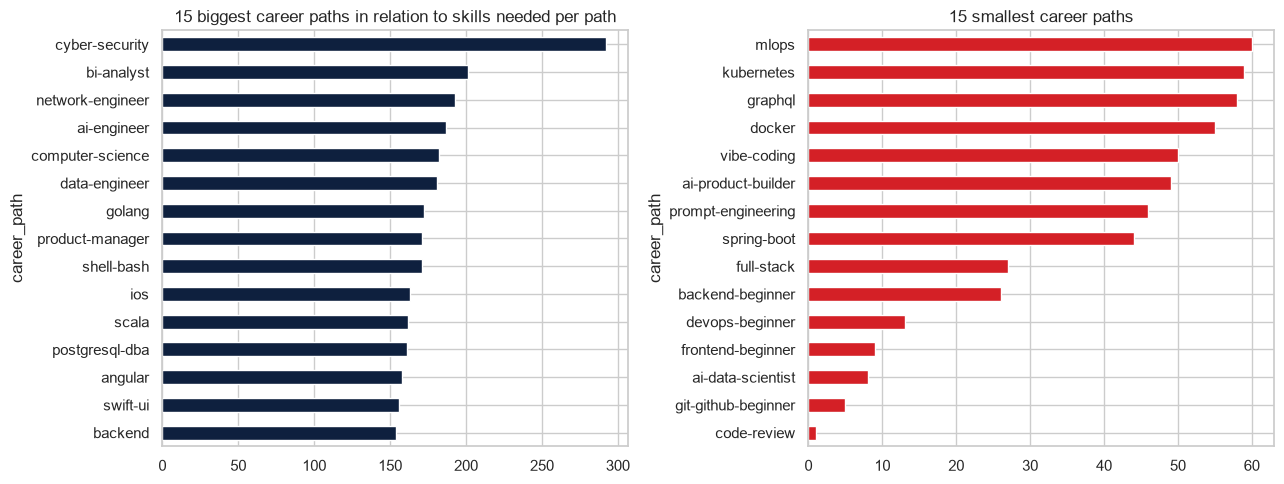

In [10]:
counts = df["career_path"].value_counts()
print("Number of career paths are:", counts.size)
print(counts.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
counts.head(15).plot(kind="barh", ax=axes[0], color="#0E203E")
axes[0].set_title("15 biggest career paths in relation to skills needed per path")
axes[0].invert_yaxis()
counts.tail(15).plot(kind="barh", ax=axes[1], color="#D42026")
axes[1].set_title("15 smallest career paths")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Decision** Because some paths have very few skills, we dropped them because a 5-fold cross validation needs at least 5 examples per class in every split. Therefore we only kept those career paths with at least 30 skills

In [20]:
# Keep only career paths with at least 30 skill nodes
MIN_SKILLS = 30
small_paths = counts[counts < MIN_SKILLS]
print("paths removed:", small_paths.to_dict())

before = len(df)
df = df[df["career_path"].isin(counts[counts >= MIN_SKILLS].index)].reset_index(drop=True)
print(f"Dropped {before-len(df)} rows from {len(small_paths)} small paths, currently {len(df)} rows remaining and ",f"{df["career_path"].nunique()} career paths")

paths removed: {'full-stack': 27, 'backend-beginner': 26, 'devops-beginner': 13, 'frontend-beginner': 9, 'ai-data-scientist': 8, 'git-github-beginner': 5, 'code-review': 1}
Dropped 89 rows from 7 small paths, currently 10204 rows remaining and  86 career paths


### Exploratory data analysis EDA
This is part of understanding the data, but we do it on the cleaned data so the numbers match what the model sees

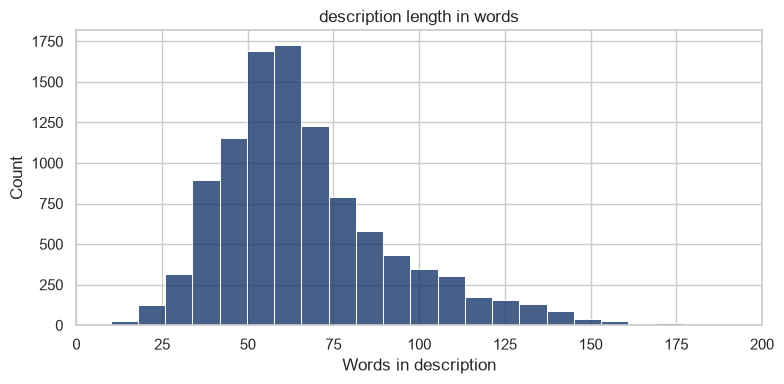

count    10293.0
mean        67.2
std         27.5
min         10.0
25%         50.0
50%         62.0
75%         79.0
max        487.0
Name: desc_words, dtype: float64


In [11]:
plt.figure(figsize=(8,4))
sns.histplot(df["desc_words"], bins=60, color="#092B62")
plt.title("description length in words")
plt.xlabel("Words in description")
plt.xlim(0,200)
plt.tight_layout()
plt.show()

print(df["desc_words"].describe().round(1))

Checking how often does each kind of learning resource exist

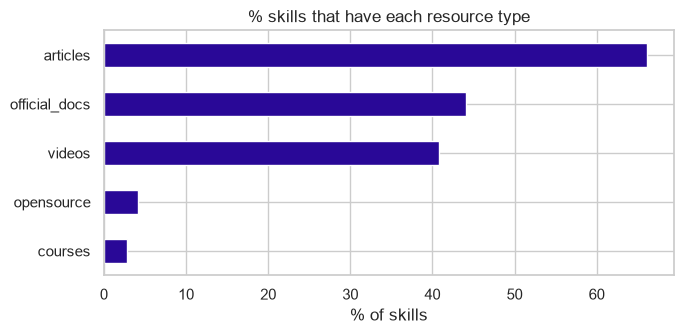

courses           2.8
opensource        4.2
videos           40.8
official_docs    44.1
articles         66.1
dtype: float64
9.5% skills with no resource link at all


In [12]:
resource_cols = ["articles", "official_docs", "videos", "opensource", "courses"]
coverage = (df[resource_cols].notna().mean()*100).round(1).sort_values()
coverage.plot(kind="barh", figsize=(7, 3.5), color="#290897")
plt.title("% skills that have each resource type")
plt.xlabel("% of skills")
plt.tight_layout()
plt.show()

no_resource = (df[resource_cols].notna().sum(axis=1) == 0).mean()*100
print(coverage)
print(f"{no_resource:.1f}% skills with no resource link at all")

Checking for the most distinctive words per career path (highest average TF-IDF score).

In [13]:
# This checks that each path has its own vocabulary which the model will rely on
probe = TfidfVectorizer(stop_words="english", min_df=2)
X_probe = probe.fit_transform(df["text"])
terms = np.array(probe.get_feature_names_out())

for path in ["cyber-security", "android", "data-engineer", "product-manager", "devops"]:
    rows = (df["career_path"] == path).values
    mean_scores = np.asarray(X_probe[rows].mean(axis=0)).ravel()
    top = terms[mean_scores.argsort()[::-1][:8]]
    print(f"{path:16s} -> {', '.join(top)}")


cyber-security   -> security, network, access, systems, data, cybersecurity, devices, information
android          -> android, app, kotlin, ui, apps, jetpack, google, user
data-engineer    -> data, cloud, storage, database, infrastructure, systems, etl, warehouse
product-manager  -> product, manager, market, managers, user, management, understanding, customer
devops           -> cloud, infrastructure, applications, server, management, platform, servers, software


### EDA Observations

1. **The classes are imbalanced** - Where after cleaning, the largest path `cyber-security` had 292 skills which was almost 10 times as many as the smallest path
2. **Many skills are shared across roadmaps** - Around 1,000 skill titles appear on more than one roadmap e.g. "Git". This sets a ceiling on accuracy where a git node belongs to many careers
3. **Descriptions are short and consistent paragraphs** - Most descriptions are 50 to 80 words
4. **Each career path has a recognisable vocabulary** - e.g. Security terms for cyber-security

In [21]:
# The final modelling dataset
final = df[["career_path", "title", "text"]].copy()
print("(rows, columns):", final.shape, "career paths: ", final["career_path"].nunique())

print(f"Original raw rows: {len(raw)}")
print(f"Final rows: {len(final)} ({len(raw)-len(final)} removed, {100*(len(raw)-len(final))/len(raw):.1f}%)")
final.head()

(rows, columns): (10204, 3) career paths:  86
Original raw rows: 10634
Final rows: 10204 (430 removed, 4.0%)


,career_path,title,text
0,ai-agents,Acting / Tool Invocation,acting tool invocation. acting also called tool invocation is the step where the ai chooses a tool and runs it to ge...
1,ai-agents,Agent Loop,agent loop. an agent loop is the cycle that lets an ai agent keep working toward a goal. first the agent gathers fre...
2,ai-agents,Agno,agno. agno is a python framework designed to streamline the process of building ai agents. it offers tools and abstr...
3,ai-agents,Anthropic Tool Use,anthropic tool use. anthropic tool use lets you connect a claude model to real software functions so the agent can d...
4,ai-agents,API Requests,api requests. api requests let an ai agent ask another service for data or for an action. the agent builds a short m...


### 3. Describe the modelling approach taken on the identified base model. Ensure you have applied appropriate measures as guided by other similar approaches to verify the validity of the results e.g. applying elbow method for K-means clustering, cross validation for classification and regularisation for regression tasks.

### Base model: TF-IDF + Logistic Regression

1. **TF-IDF** (Term Frequency-Inverse Document Frequency) to turn each skill text into a list of numbers, 1 per word. A word scores high when it is frequent in this text but rare across the whole dataset e.g. "kubernetes" and it scores low when it is common everywhere e.g. "use"
2. **Logistic regression** - learns a weight for every word for every career path ,and to classify a new text it adds up the weights of the words present and turns the total into a probability for each career path. We used logistic regression because it is fast and outputs probabilities, enabling our app to show something like top 3 most likely career paths

### Validation Plan
- **Train/test split (80/20, stratified)** - Split into 80 20 and test set is only used once at the end
- **Hyper parameter tuning with 5-fold stratified cross-validation** (hyper parameters are settings we choose before training, they are not learned from the data) - where we split the 80% training into 5 chunks and we learn from 4 chunks and test from the 5th and we repeat 5 times so each chunk gets a turn as the practice test. Then average the 5 scores. We will tune `C` to control how closely the model fits the training data. A small `C` is where the model will learn general patterns and ignore small details, while a large `C` is where the model fits training examples closely. If it fits them too closely it *overfits*, meaning it memorises the training data and does worse on new text
- **Metrics** - Accuracy(involves what % did it get right), Macro-F1(involves how well it did on each career averaged equally), Top 3 accuracy(involves if the correct career was in its top 3 guesses )


In [22]:
X = final["text"]
y = final["career_path"]

# Holding out 20% as final untouched set, stratify=y keeps every career path in the same proportion in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train on:", X_train.shape[0], "rows", "test on: ", X_test.shape[0], "rows")


Train on: 8163 rows test on:  2041 rows


In [23]:
# The pipeline bundles TF-IDF and the classifier so that inside cross-validation TF-IDF is
# refitted on each training fold only which prevents test words from leaking into training

def make_tfidf():
    return TfidfVectorizer(
        stop_words="english", #dropping very common words like and, the
        ngram_range=(1,2), #making the model read single words and two words phrases
        min_df=2, #ignore words that only appear in fewer than 2 descriptions
        sublinear_tf=True, #dampening the effect of a word repeated many times
    )

base_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(max_iter=2000)) #logistic regression learns words weights by adjusting them gradually in many small rounds, the default limit is 100, but 2000 gives it enough rounds to finish properly

])

# A rule for splitting data into practice and test folds, 5 folds and mixes the rows before
# splitting and uses the seed of 42 so the shuffle is the same everytime and results are
# reproducible
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [24]:
# Hyperparameter search with regularization strength C and n-gram range
param_grid = {
    "clf__C": [1, 10, 30],
    "tfidf__ngram_range": [(1,1), (1,2)],
}

start = time.time()
grid = GridSearchCV(base_pipeline, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"grid search finished in {time.time() - start:.0f}s")
print("Best settings:", grid.best_params_)
print(f"Best mean cross-validation macro-F1: {grid.best_score_:.3f}")

grid search finished in 313s
Best settings: {'clf__C': 30, 'tfidf__ngram_range': (1, 2)}
Best mean cross-validation macro-F1: 0.696


It is worth noting that the code above consumed a significant amount of RAM, around 10GB because of the line `n_jobs=-1` which allows it to utilize all the CPU cores at once

In [25]:
# Showing every combination tried so we can see the effect of regularisation
results = pd.DataFrame(grid.cv_results_)[
    ["param_clf__C", "param_tfidf__ngram_range", "mean_test_score", "std_test_score"]
].rename(columns={"param_clf__C": "C", "param_tfidf__ngram_range": "ngrams",
                  "mean_test_score": "cv_macro_f1", "std_test_score": "std"})
results["ngrams"] = results["ngrams"].astype(str)
results.sort_values("cv_macro_f1", ascending=False).round(3)

,C,ngrams,cv_macro_f1,std
5,30,"(1, 2)",0.696,0.010
3,10,"(1, 2)",0.690,0.010
4,30,"(1, 1)",0.690,0.009
2,10,"(1, 1)",0.689,0.010
0,1,"(1, 1)",0.643,0.008
1,1,"(1, 2)",0.621,0.007


Grid search showed that weaker regularisation (C ≥ 10) gave better results than stronger regularisation (C = 1), which did not fit the data well. The best result was achieved with C = 30 using unigrams and bigrams, with a macro-F1 score of 0.696 ± 0.010. However, the top four settings had similar results, showing that increasing C beyond 10 made little difference in performance.

### Base model evaluation on the held-out test set

In [26]:
best_model = grid.best_estimator_   # already re-trained on the full training set by GridSearchCV

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
test_top3 = top_k_accuracy_score(y_test, y_proba, k=3, labels=best_model.classes_)

print(f"Test accuracy:       {test_acc:.3f}")
print(f"Test macro-F1:       {test_f1:.3f}")
print(f"Test top-3 accuracy: {test_top3:.3f}   (true path is among the model's 3 best guesses)")
print(f"Random guessing would score about {1 / y.nunique():.3f} accuracy")


Test accuracy:       0.726
Test macro-F1:       0.725
Test top-3 accuracy: 0.882   (true path is among the model's 3 best guesses)
Random guessing would score about 0.012 accuracy


Per career path results. **Precision** - when the model says a path, how often it is right. **Recall** - out of all the test skills that really belong to a path, how many it found. **F1** - one score that balances precision and recall. **Support** - how many test skills that path has

In [27]:
# Per career path results showing which were easy and which are hard
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T
per_class = report.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score")

print("8 Hardest career paths:")
display(per_class.head(8)[["precision", "recall", "f1-score", "support"]].round(2))
print("8 easiest career paths:")
display(per_class.tail(8)[["precision", "recall", "f1-score", "support"]].round(2))

8 Hardest career paths:


,precision,recall,f1-score,support
r-programming,0.11,0.12,0.11,26.0
r,0.15,0.15,0.15,26.0
backend,0.24,0.19,0.21,31.0
devsecops,0.36,0.21,0.27,19.0
ai-product-builder,1.00,0.20,0.33,10.0
mlops,0.36,0.33,0.35,12.0
frontend,0.40,0.36,0.38,22.0
java,0.50,0.33,0.40,18.0


8 easiest career paths:


,precision,recall,f1-score,support
power-bi,0.96,0.93,0.95,29.0
kotlin,0.94,0.97,0.95,30.0
php,0.92,1.00,0.96,24.0
redis,1.00,0.93,0.96,29.0
product-manager,0.94,1.00,0.97,34.0
mongodb,1.00,0.95,0.98,21.0
engineering-manager,1.00,0.96,0.98,27.0
ai-red-teaming,1.00,1.00,1.00,13.0


Trying the base model on a few student sentences. After predicting the career path we find the closest skills on that path with **cosine similarity**, which measures how much two TF-IDF vectors point the same way (1 means the same words, 0 means no words in common)

In [28]:
# Pre-compute TF-IDF vectors for every skill once, using the trained model's vectoriser
tfidf = best_model.named_steps["tfidf"]
skill_vectors = tfidf.transform(final["text"])

def recommend(student_text, top_paths=3, top_skills=5):
    """Return the most likely career paths and the closest skills for a student's free-text interest."""
    cleaned = clean_text(student_text)
    proba = best_model.predict_proba([cleaned])[0]
    best = np.argsort(proba)[::-1][:top_paths]

    print(f'Student: "{student_text}"')
    for rank, idx in enumerate(best, 1):
        print(f"  {rank}. {best_model.classes_[idx]:20s} probability {proba[idx]:.2f}")

    # Retrieval step: cosine similarity between the query and every skill in the top path
    top_path = best_model.classes_[best[0]]
    in_path = (final["career_path"] == top_path).values
    sims = (skill_vectors[in_path] @ tfidf.transform([cleaned]).T).toarray().ravel()
    closest = final.loc[in_path, "title"].values[np.argsort(sims)[::-1][:top_skills]]
    print(f"  Closest skills on the '{top_path}' roadmap: {', '.join(closest)}\n")

recommend("I want to build mobile apps for Android phones")
recommend("I like protecting systems from hackers and analysing attacks")
recommend("I enjoy working with data pipelines and large databases")
recommend("I want to train machine learning models")
recommend("I want to be a quantitative programmer")

Student: "I want to build mobile apps for Android phones"
  1. android              probability 0.66
  2. data-engineer        probability 0.03
  3. backend              probability 0.02
  Closest skills on the 'android' roadmap: Activity, Jetpack Benchmark, Hilt, Google Play Services, Storage

Student: "I like protecting systems from hackers and analysing attacks"
  1. cyber-security       probability 0.13
  2. backend              probability 0.04
  3. software-architect   probability 0.03
  Closest skills on the 'cyber-security' roadmap: APT, HackTheBox, Common Hacking Tools, Bus, Salting

Student: "I enjoy working with data pipelines and large databases"
  1. data-engineer        probability 0.58
  2. python-data-analysis probability 0.04
  3. forward-deployed-engineer probability 0.03
  Closest skills on the 'data-engineer' roadmap: Data Pipelines, Luigi, Skills and Responsibilities, Prefect, What is Data Engineering?

Student: "I want to train machine learning models"
  1. mlops 

### 4. Determine other methods that can be used to further validate the results of the base model. 

To validate performance of the base model an effective method is to benchmark it against alternative algorithms. This can include building several candidate models e.g. Naive baseline(majority class dummy classifier), a probabilistic model(Multinomial naive bayes), a distance based model(Cosine K-Nearest neighbours) each sharing the same TF-IDF extraction pipeline to ensure fair comparison without data leakage.

Each candidate can be evaluated through 5-fold stratified cross validation on the training set to check stability and consistency across folds. By us comparing their accuracy and macro-F1 scores side by side in a structured benchmark we can confirm if the model's performance is actually strong or an alternative architecture yields superior and reliable results

### Model comparison
Every candidate gets the same TF-IDF settings and the same 5 folds of the training set, so the comparison is fair. We also added a **Linear SVM** (support vector machine, it draws the boundaries between career paths as far from the training examples as it can) because it is a common strong model for text. For logistic regression we use the best settings from the grid search.

We also check which models can give a probability for each career path, because the app needs one (see the final model below)

In [29]:
best_C = grid.best_params_["clf__C"]
best_ngrams = grid.best_params_["tfidf__ngram_range"]

candidates = {
    "Dummy (always the biggest path)": DummyClassifier(strategy="most_frequent"),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Cosine KNN (k=10)": KNeighborsClassifier(n_neighbors=10, metric="cosine", weights="distance"),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE),
    f"Logistic Regression (C={best_C})": LogisticRegression(C=best_C, max_iter=2000),
}

rows = []
start = time.time()
for name, clf in candidates.items():
    pipe = Pipeline([("tfidf", make_tfidf().set_params(ngram_range=best_ngrams)), ("clf", clf)])
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv_accuracy": cv_scores["test_accuracy"].mean(),
        "cv_macro_f1": cv_scores["test_f1_macro"].mean(),
        "std": cv_scores["test_f1_macro"].std(),
        "gives probabilities": hasattr(clf, "predict_proba"),
    })
print(f"comparison finished in {time.time() - start:.0f}s")

comparison = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
comparison.round(3)

comparison finished in 94s


,model,cv_accuracy,cv_macro_f1,std,gives probabilities
0,Linear SVM,0.715,0.708,0.009,False
1,Logistic Regression (C=30),0.700,0.696,0.010,True
2,Cosine KNN (k=10),0.577,0.564,0.009,True
3,Multinomial Naive Bayes,0.437,0.398,0.006,True
4,Dummy (always the biggest path),0.029,0.001,0.000,True


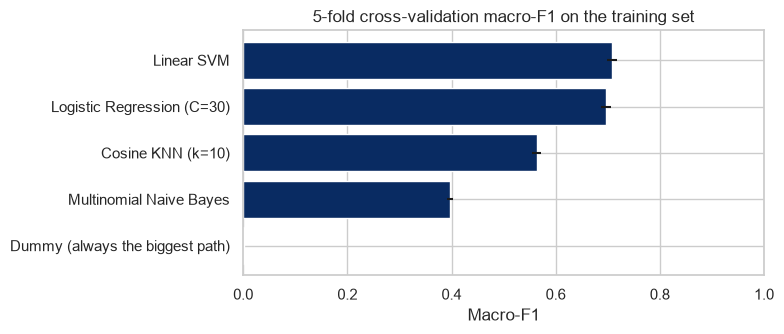

Linear SVM minus logistic regression: +0.011 macro-F1 (fold to fold std is about 0.010)


In [30]:
plot = comparison.sort_values("cv_macro_f1")
plt.figure(figsize=(8, 3.5))
plt.barh(plot["model"], plot["cv_macro_f1"], xerr=plot["std"], color="#092B62")
plt.title("5-fold cross-validation macro-F1 on the training set")
plt.xlabel("Macro-F1")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

svm = comparison.set_index("model").loc["Linear SVM"]
lr = comparison.set_index("model").loc[f"Logistic Regression (C={best_C})"]
print(f"Linear SVM minus logistic regression: {svm['cv_macro_f1'] - lr['cv_macro_f1']:+.3f} macro-F1 "
      f"(fold to fold std is about {lr['std']:.3f})")

### Model comparison results
- The dummy model shows what happens with no learning at all, it scores close to zero because there are so many career paths
- Naive Bayes and KNN are far behind Linear SVM and logistic regression, which both learn a weight for every word for every career path
- Linear SVM came out slightly ahead of logistic regression, but the gap is about the same size as the spread between folds, so the two are practically level

### Final model

**Why logistic regression and not linear SVM** - Linear SVM was only slightly better but it gives a score, not a probability. The app needs probabilities: it shows the top 3 career paths with a probability for each, it orders the roadmap by how typical a skill is of the path, and it gives each opportunity a relevance %. Logistic regression was practically level with SVM and gives all of these, so we kept it.

The final model uses exactly the same settings as the best base model:
- **TF-IDF** - English stop words removed, unigrams and bigrams, `min_df=2`, `sublinear_tf=True`
- **Logistic regression** - the best `C` from the grid search, `max_iter=2000`

The differences are only in how it is trained and stored for the phone:
1. **It is trained on all the cleaned skills**, not just the 80% training set. Once the test set has shown the settings work, there is no reason to hide 20% of the skills from the app. Because this model has seen the test set, the evaluation below uses the same settings trained on the 80% only
2. **The weights are stored as float16** so the model file is small enough for the phone
3. **The app does the maths itself in Kotlin** - TF-IDF, then the logistic regression scores, then **softmax**, which turns the score of every path into probabilities that add up to 1. We copy that maths below with numpy so we can test exactly what the phone runs. For TF-IDF we use scikit-learn's vectoriser because the app's Kotlin version is checked against it by a unit test

In [31]:
# Final model: same settings as the best base model, trained on every cleaned skill
final_tfidf = make_tfidf().set_params(ngram_range=best_ngrams)
final_clf = LogisticRegression(C=best_C, max_iter=2000)
final_clf.fit(final_tfidf.fit_transform(final["text"]), final["career_path"])

print(f"Final model trained on {len(final)} skills, {len(final_clf.classes_)} career paths, "
      f"{len(final_tfidf.vocabulary_)} TF-IDF features, C={best_C}, ngrams={best_ngrams}")

Final model trained on 10204 skills, 86 career paths, 64825 TF-IDF features, C=30, ngrams=(1, 2)


In [32]:
def to_app_format(tfidf, clf):
    """The parts of a trained model the app loads, with the weights rounded to float16 like coef.bin"""
    return {
        "tfidf": tfidf,
        "classes": list(clf.classes_),
        "coef": clf.coef_.T.astype("<f2"),   # [features x career paths], float16 like the app
        "intercept": clf.intercept_,
    }


def app_proba_from_vectors(model, X):
    """Same maths as CareerClassifier.kt: softmax(TF-IDF vector x weights + intercept)"""
    scores = X @ model["coef"].astype(np.float64) + model["intercept"]
    scores = scores - scores.max(axis=1, keepdims=True)   # stops exp() from overflowing, does not change the result
    exp = np.exp(scores)
    return exp / exp.sum(axis=1, keepdims=True)


def app_predict_proba(model, cleaned_texts):
    return app_proba_from_vectors(model, model["tfidf"].transform(cleaned_texts))


final_app = to_app_format(final_tfidf, final_clf)

### Evaluation

We compare the final model with the base model on the held-out test set (the 20% the models never trained on). The final model is scored the way the phone runs it: float16 weights and the numpy softmax above. Since the deployed final model has seen the test set, here we use the same settings trained on the 80% only, which is the base model's `best_model` with its weights rounded to float16.

We also add the base model before tuning (`C = 1`) and the dummy model so it is clear how much the tuning and the learning add.

Importance of the metrics:
- **Accuracy** - % of test skills where the top predicted path is the right one
- **Precision (macro)** - when the model says a path, how often it is right, averaged over all paths equally
- **Recall (macro)** - of the skills that really belong to a path, how many it found, averaged over all paths equally
- **Macro-F1** - one score that balances precision and recall for every path, then averages them equally so small paths count as much as big ones
- **Top-3 accuracy** - % of test skills where the right path is in the model's 3 best guesses. This is the one closest to the app, because the app shows 3 paths
- **Train accuracy** - accuracy on the training data. A big gap between train and test accuracy is a sign of overfitting

In [33]:
def scores(name, proba, classes, train_proba=None):
    pred = np.array(classes)[proba.argmax(axis=1)]
    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "macro-F1": f1_score(y_test, pred, average="macro"),
        "top-3 accuracy": top_k_accuracy_score(y_test, proba, k=3, labels=classes),
    }
    if train_proba is not None:
        row["train accuracy"] = accuracy_score(y_train, np.array(classes)[train_proba.argmax(axis=1)])
    return row


# Dummy and the base model before tuning, trained on the 80% training set
dummy = Pipeline([("tfidf", make_tfidf()), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
untuned = base_pipeline.fit(X_train, y_train)   # the pipeline from section 3 with the default C = 1

# The final model's settings trained on 80% only, run the way the app runs it (float16 weights + softmax)
eval_app = to_app_format(best_model.named_steps["tfidf"], best_model.named_steps["clf"])

evaluation = pd.DataFrame([
    scores("Dummy (always the biggest path)", dummy.predict_proba(X_test), dummy.classes_),
    scores("Base model before tuning (C=1)", untuned.predict_proba(X_test), untuned.classes_, untuned.predict_proba(X_train)),
    scores(f"Base model (C={best_C}, scikit-learn)", best_model.predict_proba(X_test), best_model.classes_, best_model.predict_proba(X_train)),
    scores(f"Final model as the app runs it (float16)", app_predict_proba(eval_app, X_test), eval_app["classes"], app_predict_proba(eval_app, X_train)),
]).set_index("model")
evaluation.round(3)

,accuracy,precision (macro),recall (macro),macro-F1,top-3 accuracy,train accuracy
model,,,,,,
Dummy (always the biggest path),0.029,0.000,0.012,0.001,0.048,NaN
Base model before tuning (C=1),0.675,0.711,0.649,0.654,0.854,0.873
"Base model (C=30, scikit-learn)",0.726,0.747,0.723,0.725,0.882,0.984
Final model as the app runs it (float16),0.726,0.747,0.723,0.725,0.882,0.984


In [34]:
# Does rounding the weights to float16 change anything?
base_proba = best_model.predict_proba(X_test)
app_proba = app_predict_proba(eval_app, X_test)
same_top = (base_proba.argmax(axis=1) == app_proba.argmax(axis=1)).mean()
print(f"Same top career path for {same_top:.1%} of test skills")
print(f"Largest probability difference: {np.abs(base_proba - app_proba).max():.4f}")

Same top career path for 100.0% of test skills
Largest probability difference: 0.0006


### Evaluation results
- The final model, run the way the phone runs it, gets the same accuracy, macro-F1 and top-3 accuracy as the base model, so storing the weights as float16 and doing the maths in Kotlin costs nothing
- Tuning `C` from 1 to the grid search's best value is what improved the base model, on every metric
- Train accuracy is a lot higher than test accuracy, so the model does overfit a bit. We still keep the tuned `C` because what matters is the score on unseen data, and cross-validation picked it
- Top-3 accuracy is much higher than accuracy because of the shared skills from EDA observation 2: when the model is wrong, the right path is usually one of its next guesses, and the app shows 3 paths so the student can still pick it

### Explainability

The app does not only show an answer but also shows why. We copy the app's steps here using the final model (the one trained on all skills, as shipped in the app):

1. **On the career cards** - every one of the 3 paths shows its probability and the 5 skills on that path that are closest to what the student typed (cosine similarity). If the student typed a path name, e.g. "Backend", that path goes first and the card says so
2. **On each skill** - "Why it matters" is built from how *typical* the skill is of the career path (the model's probability for that path when it reads only the skill's own description) and which other roadmaps have the same skill

`match_careers` below follows `CareerMatcher.topMatches` in the app. The app also compares the text with the paths' display names (e.g. "Cyber Security"), here we only have the path ids

In [35]:
MAX_CHARS = 300   # the app's text box stops at 300 characters

# Skill vectors stored as float16 like skill_vectors.bin in the app
final_skill_vectors = final_tfidf.transform(final["text"]).tocsr()
final_skill_vectors.data = final_skill_vectors.data.astype(np.float16).astype(np.float64)


def squash(s):
    return "".join(ch for ch in s.lower() if ch.isalnum())


def match_careers(student_text, k=3, skills_per_path=5):
    """Same steps as CareerMatcher.topMatches in the app"""
    if not student_text.strip():
        return None   # the app keeps the Next button disabled, so the model never runs
    text = student_text[:MAX_CHARS]
    cleaned = clean_text(text)
    query = final_app["tfidf"].transform([cleaned])
    proba = app_proba_from_vectors(final_app, query)[0]
    classes = final_app["classes"]

    # top k paths, ties keep the class order like the app
    ranked = sorted(range(len(classes)), key=lambda i: (-proba[i], i))[:k]
    # typing a path name puts that path first
    direct = next((i for i, c in enumerate(classes) if squash(c) == squash(text)), None)
    if direct is not None and ranked[0] != direct:
        ranked = [direct] + [i for i in ranked if i != direct][:k - 1]

    matches = []
    for i in ranked:
        in_path = np.where(final["career_path"].values == classes[i])[0]
        sims = (final_skill_vectors[in_path] @ query.T).toarray().ravel()
        order = np.argsort(-sims, kind="stable")
        closest = [final["title"].iat[in_path[j]] for j in order if sims[j] > 0][:skills_per_path]
        matches.append({"path": classes[i], "probability": proba[i], "direct": i == direct,
                        "closest_skills": closest, "known_terms": query.nnz})
    return matches


def show(student_text):
    matches = match_careers(student_text)
    print(f'Student: "{student_text[:80]}{"..." if len(student_text) > 80 else ""}"')
    if matches is None:
        print("  blank text: the app does not let the student continue\n")
        return
    print(f"  words/phrases the model knows: {matches[0]['known_terms']}")
    for rank, m in enumerate(matches, 1):
        note = "   <- matches the path name you typed" if m["direct"] else ""
        skills = ", ".join(m["closest_skills"]) or "(none)"
        print(f"  {rank}. {m['path']:24s} probability {m['probability']:.2f}{note}")
        print(f"     closest skills: {skills}")
    print()


show("I want to build mobile apps for Android phones")

Student: "I want to build mobile apps for Android phones"
  words/phrases the model knows: 9
  1. android                  probability 0.74
     closest skills: Activity, Google Play Services, Jetpack Benchmark, Hilt, Development IDE
  2. data-engineer            probability 0.02
     closest skills: Mobile apps, Streamlit, Census, Smoke Testing, S3
  3. flutter                  probability 0.01
     closest skills: Bitrise, Dart Basics, CI/CD, Fast lane, Android Studio



The model is confident about android and the closest skills are all Android topics, which tells the student why that path came first.

Next, a skill that is typical of the path gets a high probability, while a general skill like Git that is on many roadmaps gets a lower one and the app says it carries over to other paths. The app also adds a line when the skill is one of the path's core topics.

In [36]:
norm_title = final["title"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()


def why_it_matters(path, title):
    """Same rules as SkillExplainer.explain in the app"""
    row = final.index[(final["career_path"] == path) & (final["title"] == title)][0]
    proba = app_proba_from_vectors(final_app, final_skill_vectors[row])[0]
    typicality = proba[final_app["classes"].index(path)]
    pct = round(typicality * 100)
    top = final_app["classes"][proba.argmax()]
    if typicality >= 0.5:
        why = f"{title} is a characteristic {path} skill: from its description alone, the TechPath model predicts {path} with {pct}% probability."
    elif typicality >= 0.15:
        why = f"{title} is clearly linked to {path}: the TechPath model gives {path} {pct}% probability from this topic's description."
    else:
        why = f"{title} is a general skill rather than one unique to {path} (the model associates it most with {top}), but it is on the {path} roadmap."
    others = sorted(set(final.loc[norm_title == norm_title[row], "career_path"]) - {path})
    if others:
        why += (f" It also appears on {len(others)} other roadmap{'s' if len(others) > 1 else ''} "
                f"({', '.join(others[:3])}{', ...' if len(others) > 3 else ''}), so it carries over if you change direction.")
    print(f"{path} / {title}  (typicality {typicality:.2f})\n  {why}\n")


why_it_matters("android", "Activity")
why_it_matters("flutter", "Git")

android / Activity  (typicality 0.99)
  Activity is a characteristic android skill: from its description alone, the TechPath model predicts android with 99% probability.

flutter / Git  (typicality 0.22)
  Git is clearly linked to flutter: the TechPath model gives flutter 22% probability from this topic's description. It also appears on 11 other roadmaps (android, aspnet-core, backend, ...), so it carries over if you change direction.



**Looking inside one prediction** - The app does not show this to the student, but it lets us check that the model uses sensible words. Logistic regression gives each path a score by adding up *TF-IDF value x weight* for every word in the text.

In [37]:
def top_words(student_text, n=8):
    cleaned = clean_text(student_text)
    x = final_app["tfidf"].transform([cleaned])
    proba = app_proba_from_vectors(final_app, x)[0]
    col = proba.argmax()
    terms = final_app["tfidf"].get_feature_names_out()
    contribution = x.data * final_app["coef"][x.indices, col].astype(np.float64)
    table = pd.DataFrame({"word or phrase": terms[x.indices], "TF-IDF": x.data,
                          "weight": final_app["coef"][x.indices, col].astype(np.float64),
                          "contribution": contribution}).sort_values("contribution", ascending=False)
    print(f'"{student_text}" -> {final_app["classes"][col]} (probability {proba[col]:.2f})')
    return table.head(n).round(3)


top_words("I want to build mobile apps for Android phones")

"I want to build mobile apps for Android phones" -> android (probability 0.74)


,word or phrase,TF-IDF,weight,contribution
0,android,0.262,18.656,4.888
1,apps,0.243,4.188,1.017
2,build,0.200,-0.019,-0.004
8,want build,0.454,-0.015,-0.007
3,build mobile,0.454,-0.025,-0.011
6,phones,0.405,-0.100,-0.041
7,want,0.256,-0.271,-0.069
4,mobile,0.270,-0.359,-0.097


"android" is the heaviest and "apps" adds a little. Words like "mobile" and "phones" even pull slightly away from android, because they also show up on other roadmaps such as flutter and ios. So the model leans on the most specific word, which is what is expected

### Testing with sample inputs

How we designed the app to Model to treat inputs:
- **Blank text** - the Next button stays disabled, so the model never runs
- **Longer than 300 characters** - the text box stops at 300 characters
- **No words the model knows** (gibberish, only stop words like "the and of", or a very short word like "hi") - the TF-IDF vector is empty, so the model can only use its intercepts (the starting score of each path). Every input like this gets the same low probabilities and no closest skills
- **Irrelevant text** (not about tech) - the model still gives 3 paths, but with low probabilities and closest skills that make little sense
- **A path name** like "Backend" - that path goes first even if the model ranked it lower

The app does not block gibberish or irrelevant text, it shows the low probabilities and the student can tap "None of these? Browse all career paths"

In [38]:
valid_inputs = [
    "I want to build mobile apps for Android phones",
    "I like protecting systems from hackers and analysing attacks",
    "I enjoy working with data pipelines and large databases",
    "I want to train machine learning models",
    "I want to design websites that look good and are easy to use",
    "Backend",
]
for text in valid_inputs:
    show(text)

Student: "I want to build mobile apps for Android phones"
  words/phrases the model knows: 9
  1. android                  probability 0.74
     closest skills: Activity, Google Play Services, Jetpack Benchmark, Hilt, Development IDE
  2. data-engineer            probability 0.02
     closest skills: Mobile apps, Streamlit, Census, Smoke Testing, S3
  3. flutter                  probability 0.01
     closest skills: Bitrise, Dart Basics, CI/CD, Fast lane, Android Studio

Student: "I like protecting systems from hackers and analysing attacks"
  words/phrases the model knows: 6
  1. cyber-security           probability 0.16
     closest skills: APT, Bus, Common Hacking Tools, Salting, Impersonation
  2. backend                  probability 0.05
     closest skills: Scrypt, HTTPS, Cookie-Based Authentication, Bcrypt, Web Security Knowledge
  3. system-design            probability 0.05
     closest skills: Security, Claim Check, Availability, Eventual Consistency, Retry

Student: "I enjoy

In [39]:
long_text = "I want to build Android apps with Kotlin and Jetpack Compose for small businesses in Nairobi. " * 5

invalid_inputs = {
    "blank": "",
    "only spaces": "     ",
    "gibberish": "asdkjh qwezx plmok",
    "too short": "hi",
    "only stop words": "the and of",
    "irrelevant": "I like cooking pasta and watching football",
    "too long": long_text,
}
for kind, text in invalid_inputs.items():
    print(f"[{kind}]")
    show(text)

[blank]
Student: ""
  blank text: the app does not let the student continue

[only spaces]
Student: "     "
  blank text: the app does not let the student continue

[gibberish]
Student: "asdkjh qwezx plmok"
  words/phrases the model knows: 0
  1. computer-science         probability 0.05
     closest skills: (none)
  2. r-programming            probability 0.03
     closest skills: (none)
  3. r                        probability 0.03
     closest skills: (none)

[too short]
Student: "hi"
  words/phrases the model knows: 0
  1. computer-science         probability 0.05
     closest skills: (none)
  2. r-programming            probability 0.03
     closest skills: (none)
  3. r                        probability 0.03
     closest skills: (none)

[only stop words]
Student: "the and of"
  words/phrases the model knows: 0
  1. computer-science         probability 0.05
     closest skills: (none)
  2. r-programming            probability 0.03
     closest skills: (none)
  3. r              

In [40]:
# Checking that the outputs change the way we expect
rows = []
for kind, text in [("valid", t) for t in valid_inputs] + list(invalid_inputs.items()):
    m = match_careers(text)
    rows.append({
        "type": kind,
        "input": text[:45],
        "top path": m[0]["path"] if m else "(model not run)",
        "probability": round(m[0]["probability"], 2) if m else None,
        "known words/phrases": m[0]["known_terms"] if m else 0,
        "closest skills shown": len(m[0]["closest_skills"]) if m else 0,
    })
display(pd.DataFrame(rows))

assert match_careers("") is None and match_careers("     ") is None, "blank text should not run the model"
no_known = [match_careers(invalid_inputs[k]) for k in ["gibberish", "too short", "only stop words"]]
assert all(m[0]["known_terms"] == 0 and not m[0]["closest_skills"] for m in no_known), "no known words -> empty vector, no skills"
assert len({round(m[0]["probability"], 6) for m in no_known}) == 1, "all empty inputs fall back to the same intercept-only answer"
assert match_careers("Backend")[0]["path"] == "backend" and match_careers("Backend")[0]["direct"], "typed path name goes first"
assert match_careers(long_text) == match_careers(long_text[:MAX_CHARS]), "only the first 300 characters are used"
assert all(match_careers(t)[0]["probability"] > max(m[0]["probability"] for m in no_known) for t in valid_inputs[:5]), \
    "valid inputs should be more confident than inputs with no known words"
print("All input checks passed")

,type,input,top path,probability,known words/phrases,closest skills shown
0,valid,I want to build mobile apps for Android phone,android,0.74,9,5
1,valid,I like protecting systems from hackers and an,cyber-security,0.16,6,5
2,valid,I enjoy working with data pipelines and large,data-engineer,0.46,9,5
3,valid,I want to train machine learning models,mlops,0.69,7,5
4,valid,I want to design websites that look good and,design-system,0.28,9,5
5,valid,Backend,backend,0.09,1,5
6,blank,,(model not run),NaN,0,0
7,only spaces,,(model not run),NaN,0,0
8,gibberish,asdkjh qwezx plmok,computer-science,0.05,0,0
9,too short,hi,computer-science,0.05,0,0


All input checks passed


Valid inputs give a confident top path with closest skills that fit, while text with no known words always falls back to the same low probabilities and no closest skills, the same as in the app. Irrelevant text is the weak spot: the model only knows tech roadmaps, so it still matches one or two common words to some path, but with a low probability

In [41]:
APP_DIR = Path("../techpath-android")   # the app repo, cloned next to this one
fixture_file = APP_DIR / "core/src/test/resources/model_parity_fixture.json"

if fixture_file.exists():
    cases = json.loads(fixture_file.read_text(encoding="utf-8"))["cases"]
    all_same = True
    for case in cases:
        proba = app_predict_proba(final_app, [clean_text(case["text"])])[0]
        ours = [final_app["classes"][i] for i in np.argsort(-proba, kind="stable")[:3]]
        theirs = [t["path"] for t in case["top3"]]
        diff = max(abs(proba[final_app["classes"].index(t["path"])] - t["p"]) for t in case["top3"])
        same = ours == theirs and diff < 2e-3
        all_same &= same
        print(f"{'same' if same else 'DIFFERENT'}  {case['text'][:55]:55s} -> {', '.join(ours)}")
    print("\nFinal model matches the app on every sample" if all_same else "\nSome samples differ from the app")
else:
    print(f"{APP_DIR} not found, skipping the check against the app")

same  I want to build mobile apps for Android phones          -> android, data-engineer, flutter
same  I like protecting systems from hackers and analysing at -> cyber-security, backend, system-design
same  I enjoy working with data pipelines and large databases -> data-engineer, forward-deployed-engineer, python-data-analysis
same  I want to train machine learning models                 -> mlops, machine-learning, data-analyst
same  I want to be a quantitative programmer                  -> computer-science, c, nodejs
same  Check [the docs](https://x.io) for C++, C# & .NET -- @o -> aspnet-core, sql, golang
same  Café ÉLAN: naïve résumé builder, React/Node.js, AWS_LAM -> nodejs, aws, nextjs

Final model matches the app on every sample


### Deployment

In [42]:
EXPORT_DIR = Path("export/model")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# vocab.txt: one term per line, in feature index order
terms = [t for t, _ in sorted(final_tfidf.vocabulary_.items(), key=lambda kv: kv[1])]
(EXPORT_DIR / "vocab.txt").write_text("\n".join(terms) + "\n", encoding="utf-8")

# idf.bin and coef.bin: little-endian float32 / float16
final_tfidf.idf_.astype("<f4").tofile(EXPORT_DIR / "idf.bin")
final_app["coef"].tofile(EXPORT_DIR / "coef.bin")

# skill_vectors.bin: uint32 count, then per skill uint16 nnz, nnz x uint16 index, nnz x float16 value
X_all = final_tfidf.transform(final["text"]).tocsr()
X_all.sort_indices()
assert X_all.shape[1] < 65536, "feature index must fit in uint16"
with open(EXPORT_DIR / "skill_vectors.bin", "wb") as f:
    f.write(np.uint32(X_all.shape[0]).astype("<u4").tobytes())
    for i in range(X_all.shape[0]):
        a, b = X_all.indptr[i], X_all.indptr[i + 1]
        f.write(np.uint16(b - a).astype("<u2").tobytes())
        f.write(X_all.indices[a:b].astype("<u2").tobytes())
        f.write(X_all.data[a:b].astype("<f2").tobytes())

# model_meta.json: same fields as the app's training script
test_proba = best_model.predict_proba(X_test)
test_pred = best_model.classes_[test_proba.argmax(axis=1)]
meta = {
    "version": date.today().isoformat(),
    "model": "TF-IDF + Logistic Regression",
    "classes": final_app["classes"],
    "n_features": len(terms),
    "intercept": [float(v) for v in final_clf.intercept_],
    "tfidf": {"stop_words": "english", "ngram_range": list(best_ngrams), "min_df": 2,
              "sublinear_tf": True, "norm": "l2", "token_pattern": final_tfidf.token_pattern},
    "logistic_regression": {"C": best_C, "max_iter": 2000, "multi_class": "multinomial (softmax)"},
    "stop_words": sorted(ENGLISH_STOP_WORDS),
    "fit_on": "all",
    "rows": int(len(final)),
    "metrics": {
        "test_accuracy": round(float(accuracy_score(y_test, test_pred)), 4),
        "test_macro_f1": round(float(f1_score(y_test, test_pred, average="macro")), 4),
        "test_top3_accuracy": round(float(top_k_accuracy_score(y_test, test_proba, k=3, labels=best_model.classes_)), 4),
        "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    },
}
(EXPORT_DIR / "model_meta.json").write_text(json.dumps(meta, indent=1), encoding="utf-8")

for f in sorted(EXPORT_DIR.iterdir()):
    print(f"{f.name:20s} {f.stat().st_size / 1e6:6.2f} MB")

coef.bin              11.15 MB
idf.bin                0.26 MB
model_meta.json        0.01 MB
skill_vectors.bin      2.20 MB
vocab.txt              0.96 MB


In [43]:
# Compare with the files the app already has (read only, nothing in the app is changed)
app_model_dir = APP_DIR / "app/src/main/assets/model"

if app_model_dir.exists():
    for name in ["vocab.txt", "idf.bin", "coef.bin", "skill_vectors.bin"]:
        same = (EXPORT_DIR / name).read_bytes() == (app_model_dir / name).read_bytes()
        print(f"{name:20s} {'same as the app' if same else 'DIFFERENT from the app'}")
    ours = json.loads((EXPORT_DIR / "model_meta.json").read_text(encoding="utf-8"))
    theirs = json.loads((app_model_dir / "model_meta.json").read_text(encoding="utf-8"))
    changed = [k for k in sorted(set(ours) | set(theirs)) if k != "version" and ours.get(k) != theirs.get(k)]
    print(f"{'model_meta.json':20s} {'same as the app' if not changed else 'DIFFERENT from the app: ' + ', '.join(changed)}"
          f"  (the version date is left out of the check)")
else:
    print(f"{app_model_dir} not found, skipping the comparison with the app")

vocab.txt            same as the app
idf.bin              same as the app
coef.bin             same as the app
skill_vectors.bin    same as the app
model_meta.json      same as the app  (the version date is left out of the check)
